<a href="https://colab.research.google.com/github/manjari-varma05/EmotionPulse/blob/main/LLM_AAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Emotion classification with RNNs,LSTMs,and GRUs:
Classifying the text into 6 emotions(sadness,joy,love,anger,fear,surprise) by comparing plain recurrent models before building an Advanced bidirectional GRU

1.Import libraries:
tensorflow/keras,HuggingFace Datasets,and evaluation tools


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#to ease the process of loading dataset
from datasets import load_dataset


2.Load Dataset:
Load the dair-ai/emotion dataset from HuggingFace

In [2]:
emotion_dataset=load_dataset("dair-ai/emotion")
train_text=emotion_dataset["train"]["text"]
train_labels=emotion_dataset["train"]["label"]
test_text=emotion_dataset["test"]["text"]
test_labels=emotion_dataset["test"]["label"]

In [3]:
label_names=emotion_dataset['train'].features['label'].names
print(label_names)

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [4]:
#creating a dataframe
df_train=pd.DataFrame({'text':train_text,
                       'label':[label_names[i] for i in train_labels]})
df_test=pd.DataFrame({'text':test_text,
                      'label':[label_names[i] for i in test_labels]})


In [5]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [6]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [7]:
df_train.isnull().sum()

,0
text,0
label,0


Exploratory Data Analysis:
Visualise class distribution across 6 emotion labels

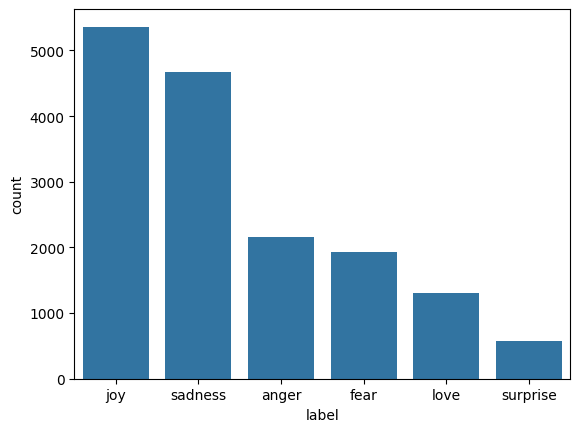

In [8]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)
plt.show()

Data Preprocessing -Using NLP:
tokenize text,pad sequences to max length 50,and convert labels to numpy array

In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=10000
tokenizer=Tokenizer(num_words=max_words,oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence=tokenizer.texts_to_sequences(df_train['text'])
test_sequence=tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence=pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence=pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

train_labels=np.array(train_labels)
test_labels=np.array(test_labels)

num_classes=len(np.unique(train_labels))

print("Vocabulary size:",len(tokenizer.word_index))
print("Number of classes:",num_classes)
print("Max length of each input sentence:",padded_train_sequence.shape[1])


Vocabulary size: 15213
Number of classes: 6
Max length of each input sentence: 50


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    padded_train_sequence,
    train_labels,
    test_size=0.2,
    random_state=42,
    stratify=train_labels
)

Shared training utilities:
Compute balanced class weigths to handle dataset skew and setup early stopping

In [11]:
from sklearn.utils import class_weight
import numpy as np

classes = np.unique(y_train)

class_wts = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_wt_dict = dict(zip(classes, class_wts))

In [12]:
from collections import Counter

print("Label names:", label_names)
print("Training distribution:", Counter(y_train))
print("Class weights:", class_wt_dict)

Label names: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
Training distribution: Counter({np.int64(1): 4290, np.int64(0): 3733, np.int64(3): 1727, np.int64(4): 1550, np.int64(2): 1043, np.int64(5): 457})
Class weights: {np.int64(0): np.float64(0.5714795963925351), np.int64(1): np.float64(0.4972804972804973), np.int64(2): np.float64(2.045381911153723), np.int64(3): np.float64(1.2352827639451844), np.int64(4): np.float64(1.3763440860215055), np.int64(5): np.float64(4.6681254558716265)}


In [13]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop=EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

Plain foundational models:
train plain(non bidirectional) simple RNNs,stand LSTMs and stand GRUs

In [14]:
#Model 1:Simple RNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Embedding,Dense,Dropout,LSTM,GRU
mod = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

mod.build(input_shape=(None, 50))
rnn_mod=mod.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
mod.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 50, 128)        │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,325,638 (5.06 MB)

 Trainable params: 1,325,638 (5.06 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
mod.fit(padded_train_sequence,
            train_labels,
            validation_data=(padded_test_sequence,test_labels),epochs=20,batch_size=32,validation_split=0.2,class_weight=class_wt_dict,callbacks=[early_stop])
rnn_loss,rnn_acc=mod.evaluate(padded_test_sequence,test_labels)
print("RNN Loss:",rnn_loss)
print("RNN Accuracy:",rnn_acc)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.1600 - loss: 2.0670 - val_accuracy: 0.1895 - val_loss: 1.7014
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.1373 - loss: 1.9018 - val_accuracy: 0.0430 - val_loss: 1.7950
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.1347 - loss: 1.8242 - val_accuracy: 0.0870 - val_loss: 1.8111
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.1406 - loss: 1.8098 - val_accuracy: 0.0940 - val_loss: 1.8063
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1895 - loss: 1.7014
RNN Loss: 1.7014132738113403
RNN Accuracy: 0.18950000405311584


In [16]:
#Satndard LSTM
lstm_mod = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])
lstm_mod.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history_lstm = lstm_mod.fit(
    X_train,
    y_train,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop]
)

lstm_loss, lstm_accuracy = lstm_mod.evaluate(
    padded_test_sequence,
    test_labels
)

print("Test loss:", lstm_loss)
print("Test accuracy:", lstm_accuracy)

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 33s 76ms/step - accuracy: 0.3187 - loss: 1.5997 - val_accuracy: 0.3475 - val_loss: 1.5650
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 41s 76ms/step - accuracy: 0.3238 - loss: 1.5868 - val_accuracy: 0.3480 - val_loss: 1.5627
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 41s 75ms/step - accuracy: 0.3261 - loss: 1.5773 - val_accuracy: 0.3560 - val_loss: 1.5226
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 41s 77ms/step - accuracy: 0.3321 - loss: 1.5642 - val_accuracy: 0.3480 - val_loss: 1.5607
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.3345 - loss: 1.5829 - val_accuracy: 0.3485 - val_loss: 1.5579
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 41s 77ms/step - accuracy: 0.3334 - loss: 1.5835 - val_accuracy: 0.3470 - val_loss: 1.5604
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3560 - loss: 1.5226
Test loss: 1.5225595235824585
Test accuracy: 0.35600000619888306


In [17]:
#Standard GRU
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128,input_length=50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


history_gru = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_wt_dict,
    callbacks=[early_stop]
)

gru_loss, gru_accuracy = gru_model.evaluate(
    padded_test_sequence,
    test_labels
)

print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


400/400 ━━━━━━━━━━━━━━━━━━━━ 26s 61ms/step - accuracy: 0.1475 - loss: 1.7965 - val_accuracy: 0.1359 - val_loss: 1.7878
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 41s 60ms/step - accuracy: 0.1462 - loss: 1.7950 - val_accuracy: 0.3347 - val_loss: 1.7574
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 41s 60ms/step - accuracy: 0.1587 - loss: 1.7936 - val_accuracy: 0.2906 - val_loss: 1.7689
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.1395 - loss: 1.7865
GRU Loss: 1.786520004272461
GRU Accuracy: 0.13950000703334808


Ranking and Selection:
Rank foundational models to pick the best base cell for the next phase

In [18]:
res_df=pd.DataFrame(
    {
        'Model':['RNN','LSTM','GRU'],
        'Loss':[rnn_loss,lstm_loss,gru_loss],
        'Accuracy':[rnn_acc,lstm_accuracy,gru_accuracy]
    }
).sort_values(by='Accuracy',ascending=False)
res_df
res_df

,Model,Loss,Accuracy
1,LSTM,1.522560,0.3560
0,RNN,1.701413,0.1895
2,GRU,1.786520,0.1395


Advanced bidirectional GRU:
Enhance GRU with bidirectional layers,300D embeddings and 0.5 dropout regularisation

In [19]:
from tensorflow.keras.layers import Bidirectional
BiGRU=Sequential([
    Embedding(input_dim=max_words, output_dim=300),
    Bidirectional(GRU(units=128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')]
)
BiGRU.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
BiGRU.build(input_shape=(None, 50))
BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 50, 300)        │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 50, 256)        │       330,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 50, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,454,662 (13.18 MB)

 Trainable params: 3,454,662 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
BiGRU.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_wt_dict,
    callbacks=[early_stop]
)
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(
    padded_test_sequence,
    test_labels
)
print("BiGRU loss:",BiGRU_loss)
print("BiGRU accuracy:",BiGRU_accuracy)

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 71s 170ms/step - accuracy: 0.4988 - loss: 1.1717 - val_accuracy: 0.8678 - val_loss: 0.5026
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 68s 171ms/step - accuracy: 0.8970 - loss: 0.3152 - val_accuracy: 0.9091 - val_loss: 0.2756
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 84s 176ms/step - accuracy: 0.9389 - loss: 0.1694 - val_accuracy: 0.9153 - val_loss: 0.2675
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 80s 171ms/step - accuracy: 0.9562 - loss: 0.1208 - val_accuracy: 0.9184 - val_loss: 0.2858
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 69s 172ms/step - accuracy: 0.9669 - loss: 0.0926 - val_accuracy: 0.9225 - val_loss: 0.2587
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 69s 171ms/step - accuracy: 0.9718 - loss: 0.0789 - val_accuracy: 0.9191 - val_loss: 0.2764
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 84s 177ms/step - accuracy: 0.9783 - loss: 0.0623 - val_accuracy: 0.9241 - val_loss: 0.2788
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 68s 169ms/step - accuracy: 0.9851 - loss: 0

In [21]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dropout, Dense

BiLSTM = Sequential([
    Embedding(input_dim=max_words, output_dim=300),
    Bidirectional(LSTM(units=128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(LSTM(units=64)),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

BiLSTM.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

BiLSTM.build(input_shape=(None, 50))
BiLSTM.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 50, 300)        │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 50, 256)        │       439,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 50, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,604,422 (13.75 MB)

 Trainable params: 3,604,422 (13.75 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:

history_bilstm = BiLSTM.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_wt_dict,
    callbacks=[early_stop]
)


Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 93s 225ms/step - accuracy: 0.5119 - loss: 1.1704 - val_accuracy: 0.8897 - val_loss: 0.3741
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 95s 237ms/step - accuracy: 0.9062 - loss: 0.2997 - val_accuracy: 0.9084 - val_loss: 0.3099
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 139s 230ms/step - accuracy: 0.9358 - loss: 0.1970 - val_accuracy: 0.8741 - val_loss: 0.3997


In [23]:

bilstm_loss, bilstm_accuracy = BiLSTM.evaluate(
    padded_test_sequence,
    test_labels
)

print(f"BiLSTM Test Loss: {bilstm_loss:.4f}")
print(f"BiLSTM Test Accuracy: {bilstm_accuracy:.4f}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.8720 - loss: 0.4418
BiLSTM Test Loss: 0.4418
BiLSTM Test Accuracy: 0.8720


Comparing bidirectional LSTM and bidirectional GRU

In [24]:

res_df = pd.DataFrame({
    'Model': ['BiGRU', 'BiLSTM'],
    'Loss': [

        BiGRU_loss,
        bilstm_loss
    ],
    'Accuracy': [

        BiGRU_accuracy,
        bilstm_accuracy
    ]
}).sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

res_df


,Model,Loss,Accuracy
0,BiGRU,0.260439,0.9155
1,BiLSTM,0.441761,0.8720


Overall Evaluation and Bias Analysis:
Consolidate test metrics,plot raw and normalised confusion matrices and analyse the bias

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step


<Axes: >

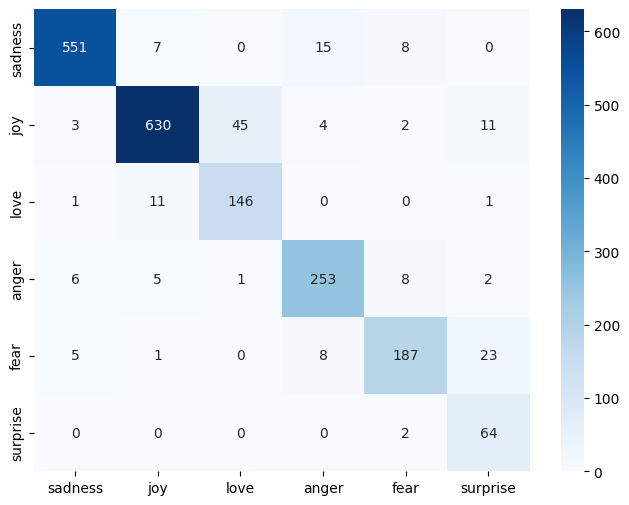

In [25]:
from sklearn.metrics import confusion_matrix
BiGRU_pred=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

conf_mat=confusion_matrix(test_labels,BiGRU_pred)
plt.figure(figsize=(8,6))
sns.heatmap(conf_mat,annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)


In [29]:
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get predictions on the test dataset
y_prob = BiGRU.predict(padded_test_sequence, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.asarray(test_labels)

# 1. Precision
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# 2. Recall
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# 3. F1-score
f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# 4. ROC-AUC (multiclass)
roc_auc = roc_auc_score(
    y_true, y_prob, multi_class="ovr", average="weighted"
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Precision: 0.9243
Recall:    0.9155
F1-score:  0.9177
ROC-AUC:   0.9948


Final Predictions:
Test the winning model on unseen sentences

In [30]:
from random import sample

sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]
sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')
sample_predictions = np.argmax(BiGRU.predict(sample_padded),axis=1)

for i in range(len(sample_texts)):
    print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


Save the final model and tokenizer:
Export trained model and tokenzier artifacts for API development

In [28]:
import os
import pickle

model_dir='Artifacts'
os.makedirs(model_dir,exist_ok=True)
#Save the bigru mod
BiGRU.save(os.path.join(model_dir,'BiGRU_model.keras'))
#Save the tokenizer
with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as f:
    pickle.dump(tokenizer,f)